In [1]:
import glob
import os
import re

import pandas as pd

import matplotlib.pyplot as plt
import numpy as np

import torch
from torch import nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv

/home/evanoreilly/Module_Code/ai_code/AIFW_GNN_Project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/evanoreilly/Module_Code/ai_code/AIFW_GNN_Project/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
def load_station_data(directory):
    air_temps = {}
    mslp = {}
    relative_humidity = {}
    station_metadata = {}

    for filepath in sorted(glob.glob(os.path.join(directory, "*.csv"))):
        filename = os.path.basename(filepath)
        station_id = os.path.splitext(filename)[0].removesuffix("_subset")

        try:
            with open(filepath, encoding="utf-8") as file:
                lines = file.readlines()

            header_row = next(
                index for index, line in enumerate(lines)
                if line.strip().lower().startswith("date,")
            )
            metadata_lines = lines[:header_row]
            station_name = next(
                (
                    line.split(":", 1)[1].strip()
                    for line in metadata_lines
                    if line.lower().startswith("station name:")
                ),
                "",
            )
            coordinates = None
            for line in metadata_lines:
                coordinates = re.search(
                    r"Latitude:\s*([-+]?\d+(?:\.\d+)?)\s*,\s*"
                    r"Longitude:\s*([-+]?\d+(?:\.\d+)?)",
                    line,
                    re.IGNORECASE,
                )
                if coordinates is not None:
                    break
            if coordinates is None:
                raise ValueError("station coordinates not found")

            station_metadata[station_id] = {
                "name": station_name,
                "lat": float(coordinates.group(1)),
                "lon": float(coordinates.group(2)),
            }

            df = pd.read_csv(
                filepath,
                skiprows=header_row,
                na_values=["", " ", "-", -999, -999.0],
            )
            df.columns = df.columns.str.strip().str.lower()
            required_columns = {"date", "temp", "rhum", "msl"}
            missing_columns = required_columns.difference(df.columns)
            if missing_columns:
                raise ValueError(f"missing columns: {sorted(missing_columns)}")

            df["Timestamp"] = pd.to_datetime(
                df["date"].astype(str).str.strip(),
                format="%d-%b-%Y %H:%M",
                errors="coerce",
            )
            df = df.dropna(subset=["Timestamp"]).set_index("Timestamp").sort_index()

            for column, values in (
                ("temp", air_temps),
                ("msl", mslp),
                ("rhum", relative_humidity),
            ):
                values[station_id] = pd.to_numeric(
                    df[column], errors="coerce"
                ).rename(station_id)
        except (OSError, StopIteration, ValueError, pd.errors.ParserError) as error:
            raise ValueError(f"Could not parse {filename}: {error}") from error

    def combine(series_by_station):
        return pd.concat(series_by_station, axis=1).sort_index()

    return (
        combine(air_temps),
        combine(mslp),
        combine(relative_humidity),
        station_metadata,
    )


DATA_DIR = "data"
df_air_temps, df_mslp, df_relative_humidity, station_metadata = load_station_data(
    DATA_DIR
)

print(f"Loaded data for {len(station_metadata)} stations.")
print("Air temperature shape:", df_air_temps.shape)
print("MSLP shape:", df_mslp.shape)
print("Relative humidity shape:", df_relative_humidity.shape)


Loaded data for 20 stations.
Air temperature shape: (26232, 20)
MSLP shape: (26232, 20)
Relative humidity shape: (26232, 20)


In [3]:
df_air_temps.at["2023-01-01 00:00:00", "hly1075"]

np.float64(6.9)

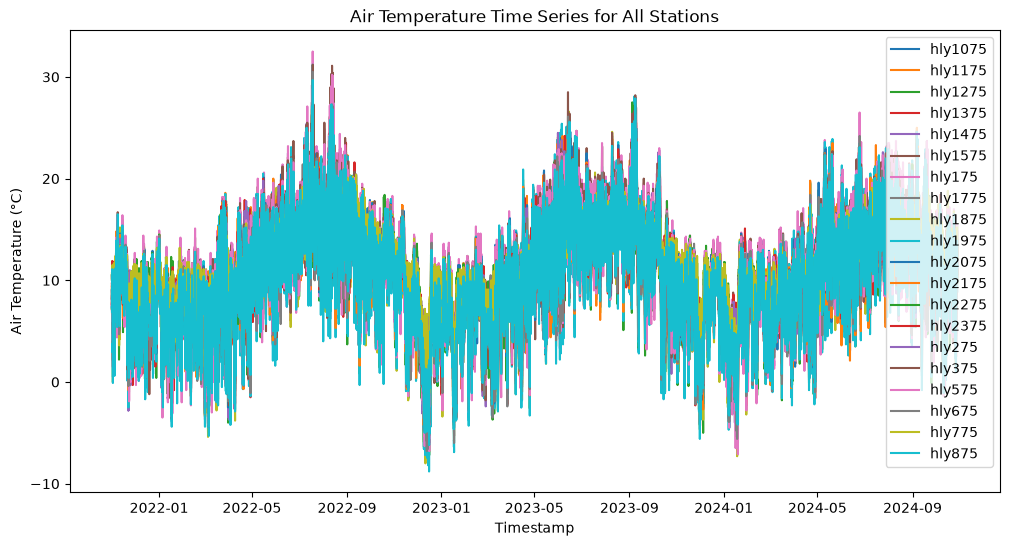

In [4]:
plt.figure(figsize=(12, 6))
for col in df_air_temps.columns:
    plt.plot(df_air_temps.index, df_air_temps[col], label=col)
plt.title("Air Temperature Time Series for All Stations")
plt.xlabel("Timestamp")
plt.ylabel("Air Temperature (°C)")
plt.legend()

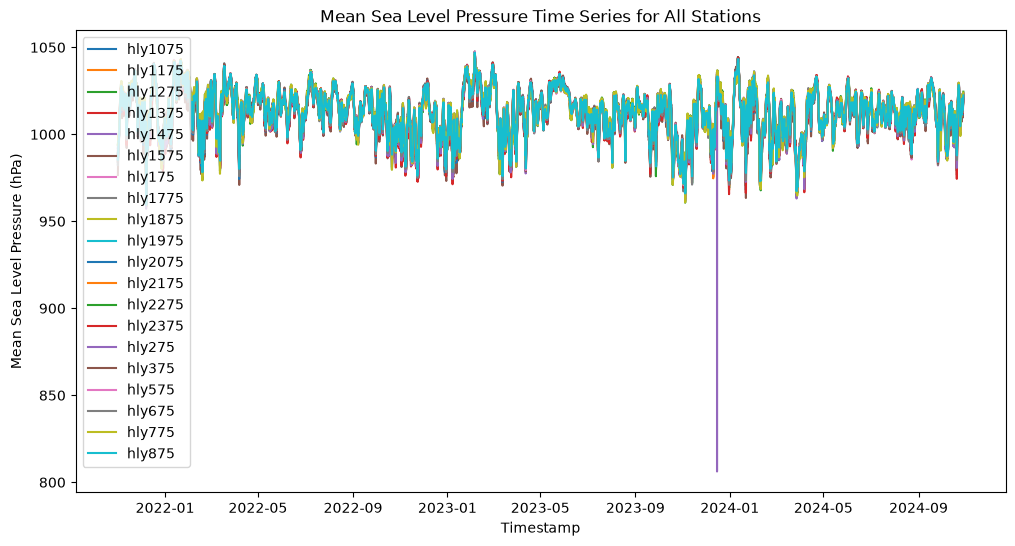

In [5]:
plt.figure(figsize=(12, 6))
for col in df_mslp.columns:
    plt.plot(df_mslp.index, df_mslp[col], label=col)
plt.title("Mean Sea Level Pressure Time Series for All Stations")
plt.xlabel("Timestamp")
plt.ylabel("Mean Sea Level Pressure (hPa)")
plt.legend()

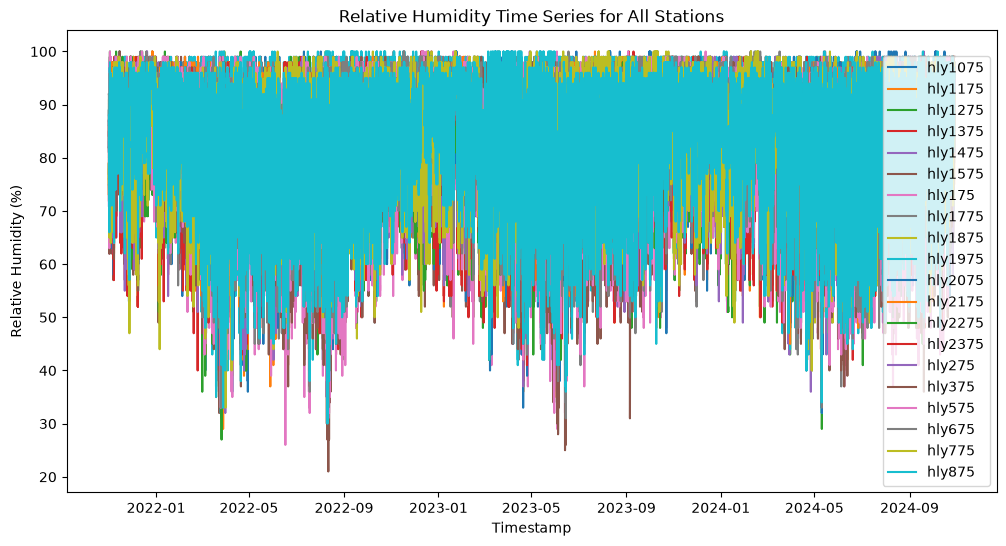

In [6]:
plt.figure(figsize=(12, 6))
for col in df_relative_humidity.columns:
    plt.plot(df_relative_humidity.index, df_relative_humidity[col], label=col)
plt.title("Relative Humidity Time Series for All Stations")
plt.xlabel("Timestamp")
plt.ylabel("Relative Humidity (%)")
plt.legend()

# Making the Graph

In [7]:
def haversine(lat1, lon1, lat2, lon2):
    # Earth radius in kilometers
    R = 6371.0 
    
    dLat = np.radians(lat2 - lat1)
    dLon = np.radians(lon2 - lon1)
    
    a = np.sin(dLat / 2)**2 + \
        np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dLon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    
    return R * c

In [8]:
# We need a fixed ordering of stations to map them to node indices
station_ids = list(station_metadata.keys())
num_nodes = len(station_ids)

# Calculate distances
dist_matrix = np.zeros((num_nodes, num_nodes))
for i, id1 in enumerate(station_ids):
    for j, id2 in enumerate(station_ids):
        if i != j:
            lat1, lon1 = station_metadata[id1]['lat'], station_metadata[id1]['lon']
            lat2, lon2 = station_metadata[id2]['lat'], station_metadata[id2]['lon']
            dist_matrix[i, j] = haversine(lat1, lon1, lat2, lon2)

In [9]:
sigma = 10.0 # Control the scale of the distance effect
weight_matrix = np.exp(-dist_matrix / sigma)

# Remove self loops for the explicit edge list (GCNConv handles self loops internally)
np.fill_diagonal(weight_matrix, 0)

# Create edge_index and edge_attr for PyTorch Geometric
edge_indices = []
edge_weights = []

for i in range(num_nodes):
    for j in range(num_nodes):
        if i != j and weight_matrix[i, j] > 0.01: # Threshold to drop very weak connections
            edge_indices.append([i, j])
            edge_weights.append(weight_matrix[i, j])

if len(edge_indices) > 0:
    edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()
    edge_attr = torch.tensor(edge_weights, dtype=torch.float)
else:
    # Fallback if only 1 station is loaded or no edges pass threshold
    edge_index = torch.empty((2, 0), dtype=torch.long)
    edge_attr = torch.empty((0,), dtype=torch.float)

print("Edge Index Shape:", edge_index.shape)
print("Number of Nodes:", num_nodes)
print("Edge Attributes Shape:", edge_attr.shape)

Edge Index Shape: torch.Size([2, 12])
Number of Nodes: 20
Edge Attributes Shape: torch.Size([12])


In [10]:
# Predict each station's air temperature six hours ahead.
# X shape: [samples, nodes, features] and Y shape: [samples, nodes, 1].
station_ids = sorted(station_metadata)
feature_frames = [
    df_air_temps[station_ids],
    df_mslp[station_ids],
    df_relative_humidity[station_ids],
]
available_dates = feature_frames[0].index
for frame in feature_frames[1:]:
    available_dates = available_dates.intersection(frame.index)
available_dates = available_dates.sort_values()

feature_dates = available_dates
target_dates = feature_dates + pd.Timedelta(hours=6)
valid = target_dates.isin(df_air_temps.index)
feature_dates = feature_dates[valid]
target_dates = target_dates[valid]

features = np.stack(
    [frame.loc[feature_dates, station_ids].to_numpy(dtype=np.float32)
     for frame in feature_frames],
    axis=-1,
)
targets = df_air_temps.loc[target_dates, station_ids].to_numpy(
    dtype=np.float32
)[..., np.newaxis]
valid_samples = np.isfinite(features).all(axis=(1, 2)) & np.isfinite(
    targets
).all(axis=(1, 2))
features = features[valid_samples]
targets = targets[valid_samples]
sample_dates = feature_dates[valid_samples]

# Keep time order so validation and test data cannot leak future observations.
train_end = int(len(features) * 0.7)
validation_end = int(len(features) * 0.85)
feature_mean = features[:train_end].mean(axis=(0, 1), keepdims=True)
feature_std = features[:train_end].std(axis=(0, 1), keepdims=True)
target_mean = targets[:train_end].mean(axis=(0, 1), keepdims=True)
target_std = targets[:train_end].std(axis=(0, 1), keepdims=True)
feature_std = np.where(feature_std == 0, 1.0, feature_std)
target_std = np.where(target_std == 0, 1.0, target_std)
features = (features - feature_mean) / feature_std
targets = (targets - target_mean) / target_std

X_tensor = torch.from_numpy(features)
Y_tensor = torch.from_numpy(targets)
X_train, Y_train = X_tensor[:train_end], Y_tensor[:train_end]
X_validation, Y_validation = (
    X_tensor[train_end:validation_end], Y_tensor[train_end:validation_end]
)
X_test, Y_test = X_tensor[validation_end:], Y_tensor[validation_end:]
train_dates = sample_dates[:train_end]
validation_dates = sample_dates[train_end:validation_end]
test_dates = sample_dates[validation_end:]

print(f"Stations: {len(station_ids)}, samples: {len(X_tensor)}")
print(f"Train: {X_train.shape}, validation: {X_validation.shape}, test: {X_test.shape}")
print(f"Edge index: {edge_index.shape}, edge attributes: {edge_attr.shape}")


Stations: 20, samples: 25798
Train: torch.Size([18058, 20, 3]), validation: torch.Size([3870, 20, 3]), test: torch.Size([3870, 20, 3])
Edge index: torch.Size([2, 12]), edge attributes: torch.Size([12])


In [11]:
class WeatherGAT(nn.Module):
    def __init__(self, in_features, hidden_dim, heads=2, forecast_horizon=1):
        super().__init__()
        self.gat1 = GATConv(
            in_channels=in_features,
            out_channels=hidden_dim,
            heads=heads,
            concat=True,
        )

        self.gru = nn.GRU(
            input_size=hidden_dim * heads,
            hidden_size=hidden_dim,
            batch_first=True,
        )

        self.fc = nn.Linear(hidden_dim, forecast_horizon)

    def forward(self, x, edge_index):
        """
        x shape: [batch_size, num_nodes, in_features]
        edge_index shape: [2, num_edges]
        """
        batch_size, num_nodes, in_features = x.shape
        
        x = x.reshape(batch_size * num_nodes, in_features)
        batch_edge_index = self._tile_edge_index(edge_index, batch_size, num_nodes)
        spatial_features = F.elu(self.gat1(x, batch_edge_index))
        
        _, hidden_state = self.gru(spatial_features.unsqueeze(1))
        predictions = self.fc(hidden_state[-1])
        return predictions.view(batch_size, num_nodes, -1)

    def _tile_edge_index(self, edge_index, batch_size, num_nodes):
        """Tiles single graph edge_index across batch dimension."""
        edge_indices = []
        for b in range(batch_size):
            edge_indices.append(edge_index + (b * num_nodes))
        return torch.cat(edge_indices, dim=1)



In [13]:
from copy import deepcopy

train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(X_train, Y_train),
    batch_size=128,
    shuffle=True,
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = WeatherGAT(in_features=X_train.shape[-1], hidden_dim=32, heads=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.MSELoss()
best_validation_loss = float("inf")
best_state = None
history = {"train_loss": [], "validation_loss": []}

for epoch in range(1, 51):
    model.train()
    train_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(batch_x, edge_index.to(device)), batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch_x.size(0)
    train_loss /= len(train_loader.dataset)

    model.eval()
    with torch.no_grad():
        validation_loss = criterion(
            model(X_validation.to(device), edge_index.to(device)),
            Y_validation.to(device),
        ).item()
    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)
    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_state = deepcopy(model.state_dict())
    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:02d}: train MSE={train_loss:.4f}, validation MSE={validation_loss:.4f}")

model.load_state_dict(best_state)
print(f"Training complete on {device}; best validation MSE={best_validation_loss:.4f}")


Epoch 01: train MSE=0.2628, validation MSE=0.1028
Epoch 10: train MSE=0.0949, validation MSE=0.0853
Epoch 20: train MSE=0.0928, validation MSE=0.0850
Epoch 30: train MSE=0.0916, validation MSE=0.0826
Epoch 40: train MSE=0.0911, validation MSE=0.0836
Epoch 50: train MSE=0.0905, validation MSE=0.0826
Training complete on cuda; best validation MSE=0.0823


In [14]:
def unscale_temperature(values):
    mean = torch.as_tensor(target_mean, dtype=values.dtype, device=values.device)
    std = torch.as_tensor(target_std, dtype=values.dtype, device=values.device)
    return values * std + mean

model.eval()
with torch.no_grad():
    predictions = unscale_temperature(
        model(X_test.to(device), edge_index.to(device))
    ).cpu()
    actual = unscale_temperature(Y_test).cpu()

# Persistence predicts that the current temperature persists for six hours.
feature_mean_tensor = torch.as_tensor(feature_mean, dtype=X_test.dtype)
feature_std_tensor = torch.as_tensor(feature_std, dtype=X_test.dtype)
persistence = (
    X_test[:, :, 0:1] * feature_std_tensor[:, :, 0:1]
    + feature_mean_tensor[:, :, 0:1]
)

def metrics(prediction, target):
    error = prediction - target
    return {"MAE": error.abs().mean().item(), "RMSE": error.square().mean().sqrt().item()}

model_metrics = metrics(predictions, actual)
persistence_metrics = metrics(persistence, actual)
print("Six-hour air-temperature forecast on the test set:")
print(f"WeatherGAT   MAE={model_metrics['MAE']:.3f}, RMSE={model_metrics['RMSE']:.3f}")
print(f"Persistence  MAE={persistence_metrics['MAE']:.3f}, RMSE={persistence_metrics['RMSE']:.3f}")


Six-hour air-temperature forecast on the test set:
WeatherGAT   MAE=1.030, RMSE=1.340
Persistence  MAE=0.610, RMSE=0.848
